# COMP9517 Lab01
> imoprt required libraries

In [13]:
# Import required libraries
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os
import math
# from pathlib import Path

# 1. Task01 Image Averaging

### 1.1 Calculate Average Image And Display
> loading 10 noisy images

In [14]:
# Define target dirctory
dir = 'COMP9517_26T2_Lab1_Images'

#  Open and load all noisy images
images = []
num_images = 10

for i in range(1, num_images + 1):
    filename = f'Sydney_{i:02d}.jpg'
    filepath = os.path.join(dir, filename)
    img = cv2.imread(filepath)

    if img is not None:
        # Convert from BGR to RGB for display
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        images.append(img_rgb)
        print(f"Loading: {filename}, Shape: {img_rgb.shape}")
    else:
        print(f"Error could not load: {filename}")

print(f"\nSuccessfully loaded {len(images)} images")

Loading: Sydney_01.jpg, Shape: (453, 660, 3)
Loading: Sydney_02.jpg, Shape: (453, 660, 3)
Loading: Sydney_03.jpg, Shape: (453, 660, 3)
Loading: Sydney_04.jpg, Shape: (453, 660, 3)
Loading: Sydney_05.jpg, Shape: (453, 660, 3)
Loading: Sydney_06.jpg, Shape: (453, 660, 3)
Loading: Sydney_07.jpg, Shape: (453, 660, 3)
Loading: Sydney_08.jpg, Shape: (453, 660, 3)
Loading: Sydney_09.jpg, Shape: (453, 660, 3)
Loading: Sydney_10.jpg, Shape: (453, 660, 3)

Successfully loaded 10 images


> Display all 10 noisy images

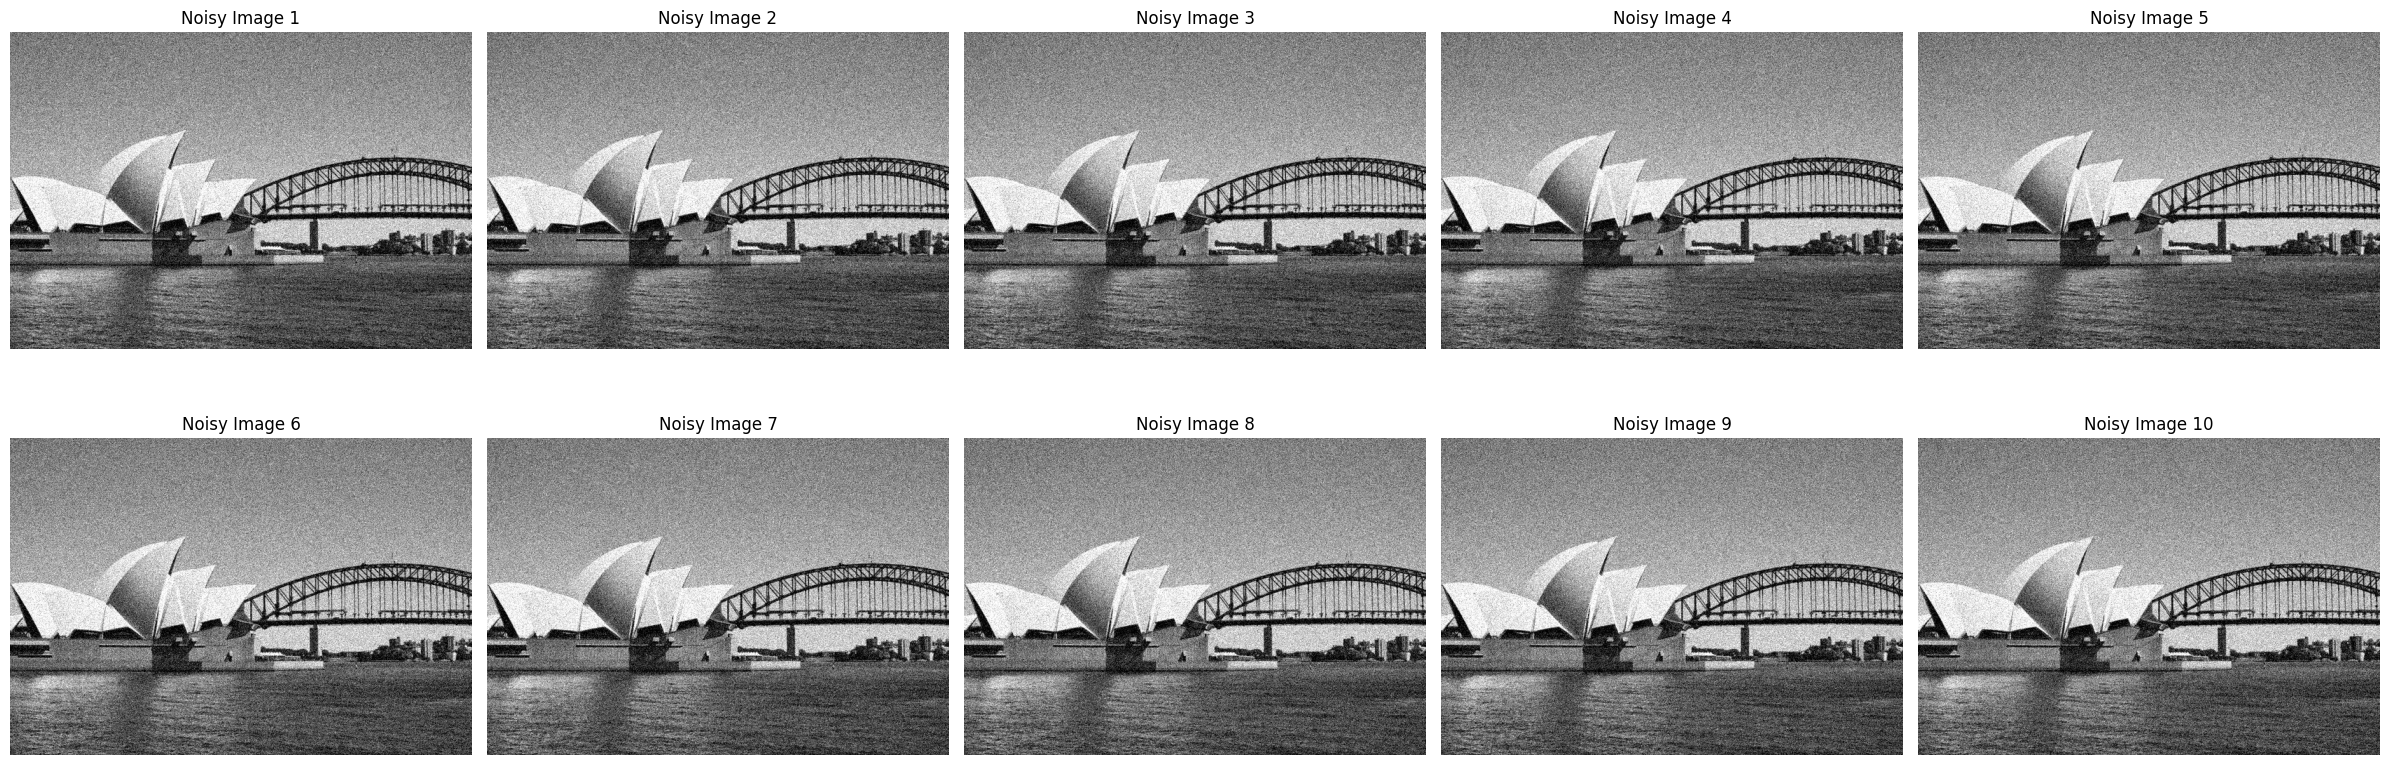

In [15]:

fig, axes = plt.subplots(2, 5, figsize=(24, 9))
axes = axes.ravel()

for idx in range(len(images)):
    axes[idx].imshow(images[idx])
    axes[idx].set_title(f'Noisy Image {idx + 1}')
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

>  Display result: single noisy image vs averaged image

Average image shape: (453, 660, 3)


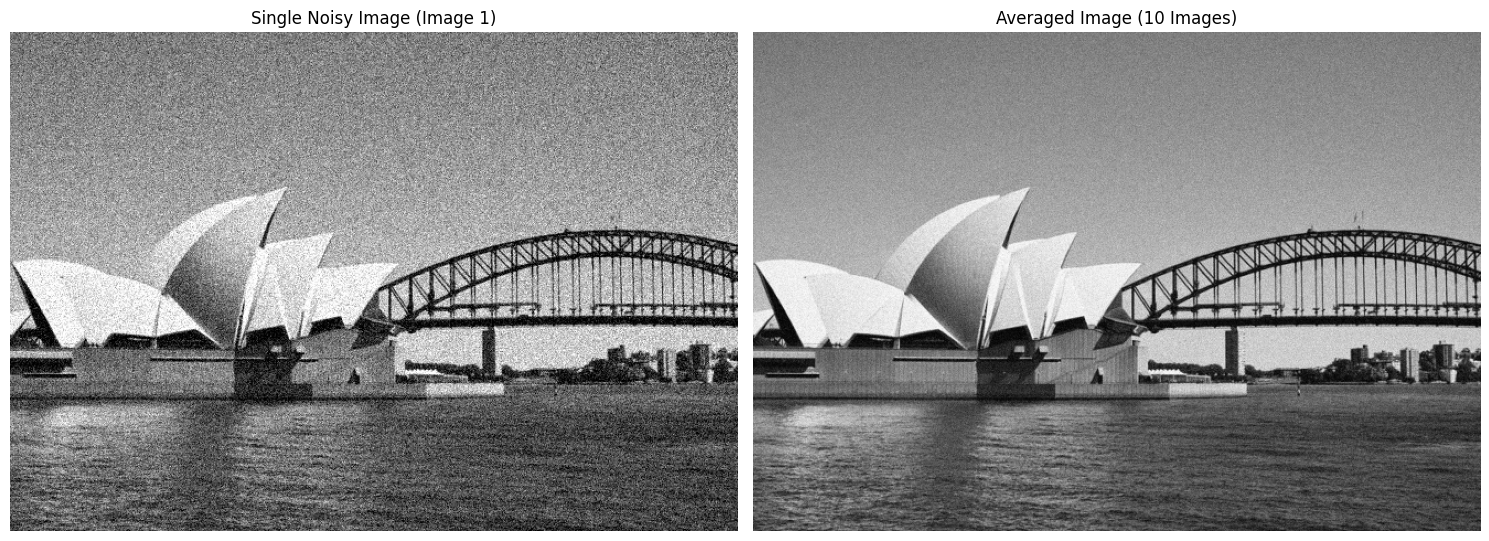

In [16]:
# Convert list of images to numpy array for easier computation
images_array = np.array(images, dtype=np.float64)

# Calculate the average image
average_image = np.mean(images_array, axis=0)

# Convert back to uint8 for display
average_image_uint8 = np.uint8(average_image)

print(f"Average image shape: {average_image_uint8.shape}")
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Show the first noised image
axes[0].imshow(images[0])
axes[0].set_title('Single Noisy Image (Image 1)')
axes[0].axis('off')

# Show the average image
axes[1].imshow(average_image_uint8)
axes[1].set_title('Averaged Image (10 Images)')
axes[1].axis('off')

plt.tight_layout()
plt.show()



## 1.2 Noise Reduction measuremanet
### 1.2.1 Theoretical noise reduction calculation
background: from what we have learned in lecture, the variance $\sigma^2$ of *N* images would reduce by the factore *N*
$$\rightarrow \text{VAR}\left[ \frac{1}{N} \sum_{i=1}^{N} n_i(x,y) \right] = \frac{1}{N^2} \sum_{i=1}^{N} \text{VAR}[n_i(x,y)] = \frac{1}{N^2} N\sigma^2(x,y) = \frac{\sigma^2(x,y)}{N}$$

- therefore,
$$\rightarrow \text{DEVIATION}\left[ \frac{1}{N} \sum_{i=1}^{N} n_i(x,y) \right] =  \frac{\sigma^2(x,y)}{\sqrt{N}}$$

- In conclusion, we can esily see the factor is: $\sqrt{N}$

Here *N* = 10, the current noise is $\frac{1}{\sqrt{10}}$ of original noise

- Then calculate this number



In [17]:
print(1/math.sqrt(10))

0.31622776601683794


- The current noise is theoritically 31.6% of the original image
- the reduction is ought to be $100\% - 31.6\% = 68.4\% $ 
### 1.2.2 Practical Noise Reduction measurement and comparation

The standard deviation of noisy image is 27.34
The standard deviation of averaged image is 11.55
The ratios of the former to the latter is 2.37


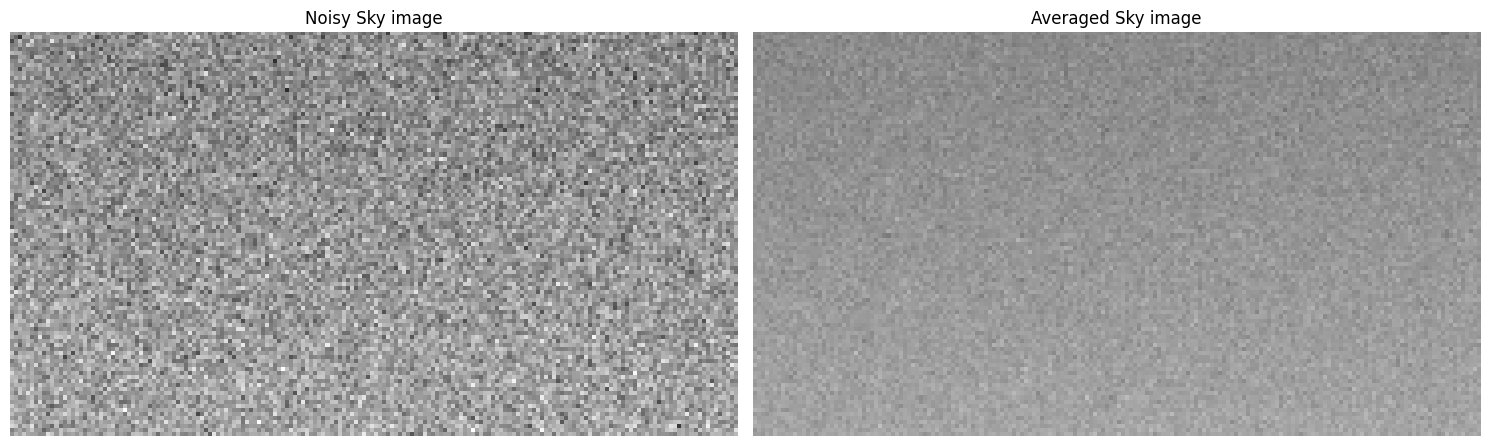

In [18]:
sky_row_start, sky_row_end = 50, 150
sky_col_start, sky_col_end = 300, 480

# Extract rectangle part

sky_noise = images[1][sky_row_start:sky_row_end, sky_col_start: sky_col_end]
sky_average = average_image_uint8[sky_row_start:sky_row_end, sky_col_start: sky_col_end]

# Calculate standard deviation of both

sky_noise_std = np.std(sky_noise)
sky_average_std = np.std(sky_average)
# sky_noise_std = np.mean(np.std(sky_noise, axis=(0, 1)))
# sky_average_std = np.mean(np.std(sky_average, axis=(0, 1)))

ratio = sky_noise_std/sky_average_std

print(f'The standard deviation of noisy image is {sky_noise_std:.2f}')
print(f'The standard deviation of averaged image is {sky_average_std:.2f}')
print(f'The ratios of the former to the latter is {ratio:.2f}')


# Display
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].imshow(sky_noise)
axes[0].axis('off')
axes[0].set_title('Noisy Sky image')


axes[1].imshow(sky_average)
axes[1].axis('off')
axes[1].set_title('Averaged Sky image')


plt.tight_layout()
plt.show()




# 2. Task02 DOG
> We present both 2D Gaussian filter kernals:

In [19]:
# define both 2 kernal
h1 = (1/16) * np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 2, 1, 0],
    [0, 2, 4, 2, 0],
    [0, 1, 2, 1, 0],
    [0, 0, 0, 0, 0]
], dtype=np.float64)
h2 = (1/256) * np.array([
    [1, 4, 6, 4, 1],
    [4, 16, 24, 16, 4],
    [6, 24, 36, 24, 6],
    [4, 16, 24, 16, 4],
    [1, 4, 6, 4, 1]
], dtype=np.float64)

## 2.1. Approach 1: compute DOG and convolve

In [20]:
# calculate DOG
dog = h1 - h2
print(f"dog is: \n{dog}")
print(f"sum of dog is: {np.sum(dog):.6f}")

# convolve the result g = f * dog = f * (h1 - h2)

g1 = np.zeros_like(average_image, dtype=np.float64)

for channel in range(3):
    g1[:, :, channel] = cv2.filter2D(
        average_image[:, :, channel],
        -1,
        dog
    )

def normalize(img):
    """normalize the result to 0.0 - 1.0"""
    min_val = img.min()
    max_val = img.max()
    return (img - min_val) / (max_val - min_val)
# We retrive result1
result1 = normalize(g1)

dog is: 
[[-0.00390625 -0.015625   -0.0234375  -0.015625   -0.00390625]
 [-0.015625    0.          0.03125     0.         -0.015625  ]
 [-0.0234375   0.03125     0.109375    0.03125    -0.0234375 ]
 [-0.015625    0.          0.03125     0.         -0.015625  ]
 [-0.00390625 -0.015625   -0.0234375  -0.015625   -0.00390625]]
sum of dog is: 0.000000


## 2.2 Approach 2: Compute separately

In [21]:
# g = f*h1 - f*h2

# calculate f*h1 and f*h2 separatly
fh1 = np.zeros_like(average_image, dtype=np.float64)
fh2 = np.zeros_like(average_image, dtype=np.float64)

# Calculate f*h1
for channel in range(3):
    fh1[:, :, channel] = cv2.filter2D(
        average_image[:, :, channel],
        -1,
        h1)
# Calculate f*h2
for channel in range(3):
    fh2[:, :, channel] = cv2.filter2D(
        average_image[:, :, channel],
        -1,
        h2)

g2 = fh1 - fh2
result2 = normalize(g2)


## 2.3 Display result of 2 different DOG-filtering approaches

<Figure size 1000x600 with 0 Axes>

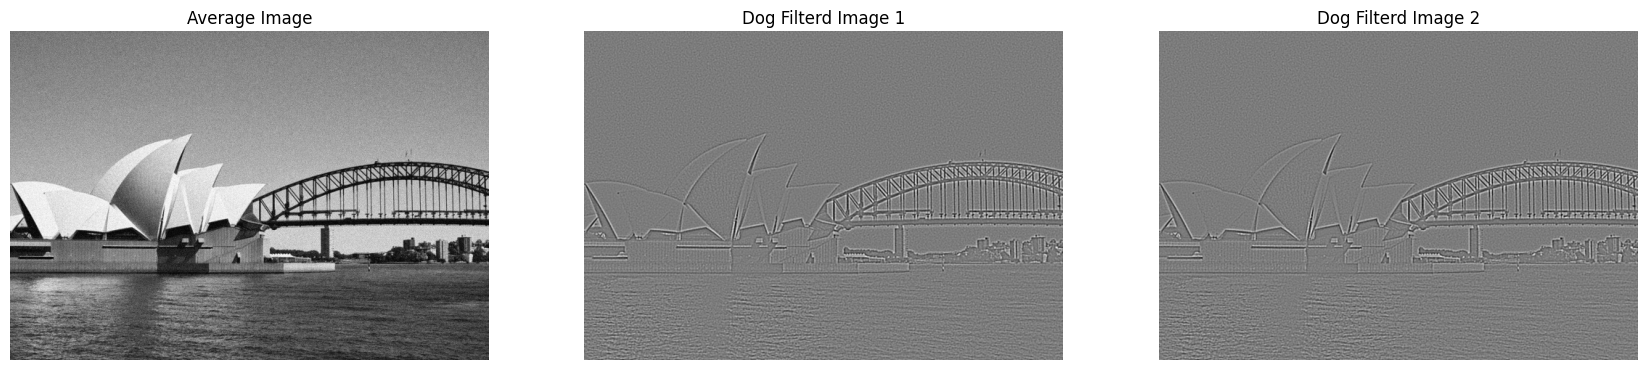

In [22]:


plt.figure(figsize=(10, 6))
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

axes[0].imshow(average_image_uint8)
axes[0].set_title('Average Image')
axes[0].axis('off')


axes[1].imshow(result1)
axes[1].set_title('Dog Filterd Image 1')
axes[1].axis('off')


axes[2].imshow(result2)
axes[2].set_title('Dog Filterd Image 2')
axes[2].axis('off')

# plt.axis('off')
plt.show()

### 2.4 Advantages of Each Approach 
**Approach1**：$g = f * (h_1 - h_2)$
- Computational effiency: In this method we only need to convolve once, compring to approach2 it is more efficient
- Lower space complexity: In this approach we do not need more space to store both $f*h_1 and f*h_2$

**Approach2**: $g = f*h_1 - f*h_2$
- Flexibility & Reuse of Intermediate Results: the image $f*h_1 and f*h_2$ can be reused by other process
- Parallel Processing Capability: these 2 process can be computed parallel which can save CPU time


# 3. Unsharp Masking
### 3.1 Compute the result and display

Take one of the DoG-filtered images from Task 2 (it does not matter which one) and multiply it with a factor of 5. 
Then add the resulting image to your average image from Task 1.

In [23]:
mask = 5 * result1
print(mask.shape)


average_float = average_image.astype(np.float64)
sharpened_image = average_float + mask

# adjust brightness
alpha = 1.1
beta = -5

adjusted_image = alpha * sharpened_image + beta
sharpened_image = np.clip(adjusted_image, 0, 255)

# Convert to uint8 for display
sharpened_image_uint8 = sharpened_image.astype(np.uint8)
# sharpened_image_uint8 = np.uint8(sharpened_image) same operation?

crop_average = average_image_uint8[250:350, 200:400]

crop_sharp = sharpened_image_uint8[250:350, 200:400]



(453, 660, 3)


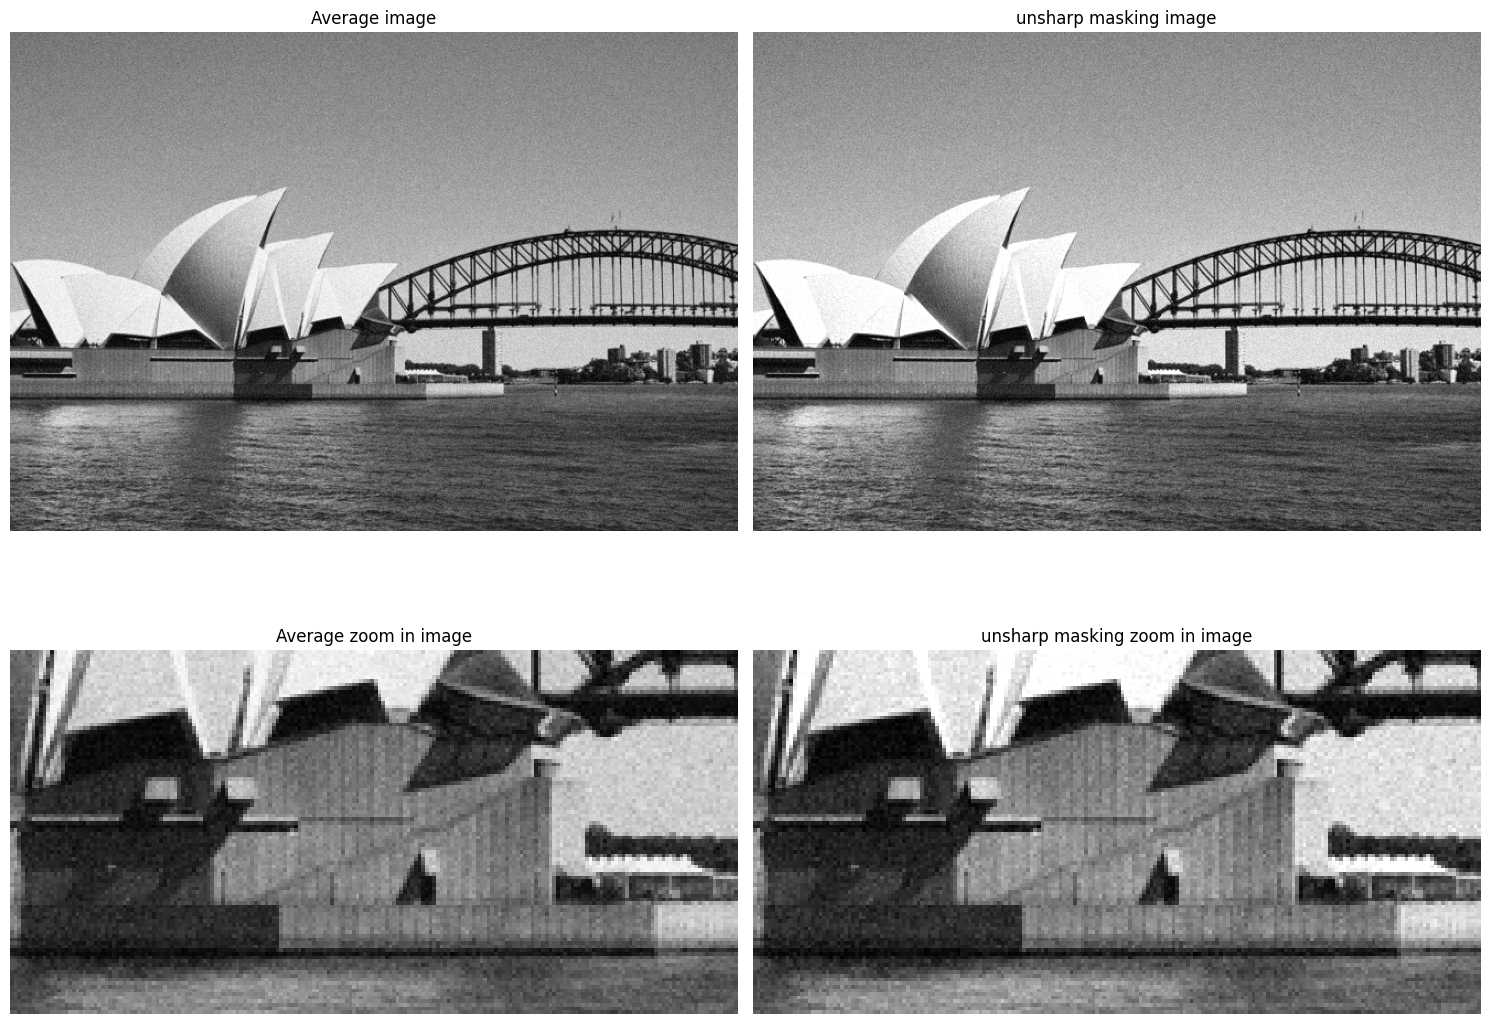

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.ravel()
axes[0].imshow(average_image_uint8)
axes[0].axis('off')
axes[0].set_title('Average image')


axes[1].imshow(sharpened_image_uint8)
axes[1].axis('off')
axes[1].set_title('unsharp masking image')


axes[2].imshow(crop_average)
axes[2].axis('off')
axes[2].set_title('Average zoom in image')


axes[3].imshow(crop_sharp)
axes[3].axis('off')
axes[3].set_title('unsharp masking zoom in image')


plt.tight_layout()
plt.show()

## 3.2 Therotical Question

### 3.2.1 In addition to edge sharpness, what else has been amplified in the output image of Task 3, which we were trying to get rid of in Task 1?
- We can see the noise is also amplified here, by observing the and comparing the sky in 2 images we can see the usharped mask zoom in image has significant noise there.
- we tried to get rid of noises
### 3.2.2 what is the intuitive explanation for why this happens?
- DOG filter would exrtract high-frequency components in the image
- intensity between edges changed rapidly, but noise is the undesired intensity change , and intensity variation, which also match high-frequency compoent
- therefore, noise would also be extract and amplified by DOG and thus enhanced in unsharped masking methos